# Pasador de la polea F — cálculo paso a paso (modelo: par de fuerzas + momento en el centro)

**Qué hace este cuaderno:** dimensiona el diámetro del pasador $d_p$ que une la polea F con el eje, con el mismo orden que tu memoria de cálculo.
**Cómo usarlo:** (1) cambia números **solo en la celda 1** (líneas `← CAMBIA`); (2) ejecuta todo en orden (Shift+Enter); (3) cada paso imprime sus ecuaciones con números.

## Tres modelos de carga (elige en la celda 1 con `MODELO`)
**`"par_centro"` (tu modelo, por defecto)**
- El eje transmite el torque $T$ al pasador como un **par concentrado en el centro**.
- El cubo reacciona con **dos fuerzas $F$ iguales y opuestas en el cambio de sección** ($y=\pm D/2$). Equilibrio: $F\cdot D = T$.
- Cortante $F$ entre las dos fuerzas; momento flector máximo $T/2$ en el centro (salto producido por el par).

**`"repartido"` (diapositiva 16 del PPT del curso, con resultantes puntuales)**
- Cubo: presión uniforme → resultante $F_D$ a $a=(D+S)/2$ del centro. Eje: presión triangular → resultante $F_P$ a $b=D/3$ del centro.
- Equilibrio: $2F_P\,b = T$ y $2F_D\,a = T$. Sin par concentrado.

**`"sin_flexion"` (montaje apretado, sin holgura; criterio clásico)**
- El agujero sostiene al pasador a lo largo de todo su largo y la carga se transfiere como **corte y aplastamiento** en el plano entre eje y cubo. **No se calcula flexión** ($M=0$).
- Fuerza por plano: `F_SIN_FLEXION = "transicion"` → $F = T/D$ (fuerzas en el cambio de sección) ; `"pared"` → $F = T/(D+S)$ (carga uniforme en cada pared del cubo, como en los apuntes D.Z.). El cortante en cada plano vale $F$ (los dos planos están en **serie**, no en paralelo).
- **Debes declarar este supuesto** (ajuste apretado) en la memoria y en el plano. Con holgura corresponden los otros dos modelos.

**Ciclo de carga (todos los modelos):** la potencia va de 0 a su máximo, así que todas las cargas van de 0 a su máximo → **esfuerzo alterno = esfuerzo medio = máximo/2**.

## Ecuaciones (se numeran igual en la memoria de cálculo)
| N° | Paso | Ecuación |
|---|---|---|
| (1) | Torque en F | $T_F = \dfrac{P_F}{\omega_{eje}}$ |
| (2a) | Fuerzas, modelo `par_centro` | $F = \dfrac{T_F}{D}$ , $\;V = F$ , $\;M_{max} = \dfrac{T_F}{2}$ |
| (2b) | Fuerzas, modelo `repartido` | $F_D=\dfrac{T_F}{2a}$ , $\;F_P=\dfrac{T_F}{2b}$ , $\;V_{max}=\lvert F_P-F_D\rvert$ , $\;M_{max}=F_D\,(a-b)$ |
| (2c) | Fuerza, modelo `sin_flexion` | $F = \dfrac{T_F}{D}$ ó $\dfrac{T_F}{D+S}$ , $\;V = F$ , $\;M_{max}=0$ |
| (3) | Corte | $\tau = \dfrac{V}{\pi d_p^2/4}$ |
| (4) | Flexión | $\sigma = \dfrac{32\,M_{max}}{\pi d_p^3}$ |
| (5) | Von Mises (máximos) | $\sigma' = \sqrt{\sigma^2 + 3\tau^2}$ |
| (6) | Aplastamiento en el cubo | $\sigma_{ap,c} = \dfrac{F_{cubo}}{d_p\,S}$ ($F_{cubo}=F$ ó $F_D$) |
| (7) | Aplastamiento en el eje (pico triangular) | $\sigma_{ap,e} = \dfrac{6\,T_F}{D^2 d_p}$ |
| (8) | Límite de fatiga corregido | $S_f = 0{,}5\,S_r\,C_c\,C_t\,C_s\,C_T\,C_i$ |
| (9) | Factores de Marin | $C_t = 0{,}879\,d_p^{-0{,}107}$ ($d_p$ en pulgadas) , $C_s = 4{,}51\,S_r^{-0{,}265}$ |
| (10) | Fatiga (Goodman) | $\dfrac{\sigma'_a}{S_f} + \dfrac{\sigma'_m}{S_r} = \dfrac{1}{N_{fat}}$ con $\sigma'_a=\sigma'_m=\sigma'/2$ |
| (11) | Fatiga del aplastamiento (compresión, $\sigma_m\le 0$) | $N_{fat} = \dfrac{S_f}{\sigma_{ap}/2}$ |
| (12) | Fluencia | $N_{y} = \dfrac{S_0}{\sigma'}$ , $\;N_{y,\tau}=\dfrac{0{,}577\,S_0}{\tau}$ , $\;N_{y,ap}=\dfrac{S_0}{\sigma_{ap}}$ |
| (13) | Diámetro mínimo | $d_{p,min} = \max\{d_p \,|\, N_{fat}\ge N_f\}$ sobre todos los criterios |


In [1]:
# ======================= 1. DATOS (aquí es lo ÚNICO que cambias) =======================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

# --- Potencia y torque ---
P_HP, rpm_motor = 10, 120      # [HP], [rpm]  motor
d_B, d_C = 60, 120             # [mm]  piñón B y engrane C (relación 1:2)
frac_F = 0.50                  # fracción de la potencia que consume la polea F   ⚠ SUPUESTO (no está en el enunciado)   ← CAMBIA

# --- Geometría de la unión ---
D = 40                         # [mm]  diámetro del eje en el pasador
S = 20                         # [mm]  cubo que sobresale a cada lado del eje   ← CAMBIA   → D_N = D + 2·S
D_N = D + 2*S                  # [mm]  diámetro exterior del cubo (= largo del pasador)

# --- Material del pasador ---   (valores que tú entregaste; confirma que vienen de la misma ficha que el eje)
nombre_mat = "SAE 1020 estirado en frío"   # ← CAMBIA
S0 = 393.0                     # [MPa] fluencia      ← CAMBIA
Sr = 469.0                     # [MPa] ruptura       ← CAMBIA

# --- Modelo de carga ---
MODELO = "sin_flexion"          # "par_centro" (par + momento en el centro) | "repartido" (diap. 16, con holgura) | "sin_flexion" (ajuste apretado)   ← CAMBIA
F_SIN_FLEXION = "transicion"   # solo para "sin_flexion":  "transicion" → F = T/D   |   "pared" → F = T/(D+S)   ← CAMBIA

# --- Criterios de diseño ---
N_f = 1.6                      # factor de seguridad a fatiga (Tabla 1, grupo 1)
Ci = 1.0                       # confiabilidad: 50 % → 1,0 | 90 % → 0,897 | 95 % → 0,868 | 99 % → 0,814   ← DECIDE
Cc, CT = 1.0, 1.0              # carga combinada ; temperatura ≤ 100 °C
Kf_pasador = 1.0               # concentrador del pasador mismo (prisma liso, sin entalla). Se aplica a la parte alterna
SERIE_DP = [8, 10, 12, 16, 20, 22, 25, 28, 30, 32, 36, 40]   # [mm] diámetros disponibles (verifica tu catálogo; ISO 2338 trae 25 y 30)
dp_adoptado = None             # None → automático (primer valor de la serie ≥ d_p,min). O escribe el tuyo, ej: 28   ← CAMBIA

## Paso 1 · Torque que transmite el pasador (ecuación 1)
A mano: $\omega_B = \dfrac{2\pi\,rpm}{60}$ ; $\omega_{eje} = \omega_B\,\dfrac{d_B}{d_C}$ ; $P_F = frac_F\cdot P$ ; $T_F = \dfrac{P_F}{\omega_{eje}}$

In [2]:
P = P_HP*746                              # [W]
w_B = rpm_motor*2*np.pi/60                # [rad/s]
w_eje = w_B*d_B/d_C                       # [rad/s]  el eje gira más lento que el motor
P_F = frac_F*P                            # [W]
T_F = P_F/w_eje                           # [N·m]  ← ecuación (1)
print(f"P = {P:.0f} W | ω_B = {w_B:.3f} rad/s | ω_eje = {w_eje:.3f} rad/s")
print(f"P_F = {frac_F:.2f}·P = {P_F:.0f} W   →   T_F = P_F/ω_eje = {T_F:.1f} N·m")

P = 7460 W | ω_B = 12.566 rad/s | ω_eje = 6.283 rad/s
P_F = 0.50·P = 3730 W   →   T_F = P_F/ω_eje = 593.6 N·m


## Paso 2 · DCL del pasador y fuerzas (ecuación 2)
**`par_centro`:** el pasador recibe el par $T_F$ del eje (en el centro) y dos fuerzas $F=T_F/D$ del cubo en $y=\pm D/2$. Un par no genera fuerza.
**`repartido`:** dos pares de fuerzas, $F_D$ (cubo) a $\pm a$ y $F_P$ (eje) a $\pm b$ del centro; su suma de momentos equilibra $T_F$.
La variable `cargas` guarda cada fuerza como (posición $y$ [mm], fuerza con signo [N], nombre).

MODELO sin_flexion (transicion):  F = 14841 N en cada plano y = ±20 mm  →  V = F, M = 0
⚠ Supuesto: pasador con ajuste apretado, sin holgura. Decláralo en la memoria y en el plano.


,Magnitud,Símbolo,Valor,Unidad
0,Torque del eje sobre el pasador,T_F,593.65,N·m
1,Fuerza F en y = +20.00 mm,F,14841.20,N
2,Fuerza F en y = -20.00 mm,F,-14841.20,N


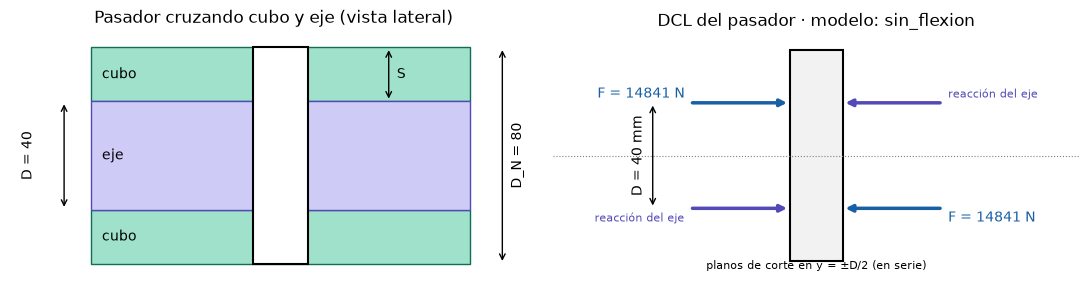

In [3]:
T_Nmm = T_F*1000                          # [N·mm]
a_, b_ = (D + S)/2, D/3                   # [mm] brazos del modelo repartido (centroides: rectángulo del cubo, triángulo del eje)
if MODELO == "par_centro":
    F = T_Nmm/D                           # [N]  ← ecuación (2a)
    cargas = [(+D/2, +F, "F"), (-D/2, -F, "F")]
    F_cubo, hay_par = F, True
    print(f"MODELO par_centro:  F = T_F/D = {T_Nmm:.0f}/{D} = {F:.0f} N   (dos fuerzas en y = ±{D/2:g} mm) + par T_F = {T_F:.1f} N·m en el centro")
elif MODELO == "repartido":
    F_D = T_Nmm/(2*a_); F_P = T_Nmm/(2*b_)   # [N]  ← ecuación (2b)
    cargas = [(+a_, +F_D, "F_D"), (+b_, -F_P, "F_P"), (-b_, +F_P, "F_P"), (-a_, -F_D, "F_D")]
    F_cubo, hay_par = F_D, False
    print(f"MODELO repartido:  F_D = T_F/(2a) = {F_D:.0f} N (a = {a_:g} mm)   |   F_P = T_F/(2b) = {F_P:.0f} N (b = {b_:.2f} mm)")
elif MODELO == "sin_flexion":
    F = T_Nmm/D if F_SIN_FLEXION == "transicion" else T_Nmm/(D + S)          # [N]  ← ecuación (2c)
    cargas = [(+D/2, +F, "F"), (-D/2, -F, "F")]      # fuerza del cubo; la del eje actúa en el MISMO plano, en sentido contrario
    F_cubo, hay_par = F, False
    print(f"MODELO sin_flexion ({F_SIN_FLEXION}):  F = {F:.0f} N en cada plano y = ±{D/2:g} mm  →  V = F, M = 0")
    print("⚠ Supuesto: pasador con ajuste apretado, sin holgura. Decláralo en la memoria y en el plano.")
else:
    raise ValueError("MODELO debe ser 'par_centro', 'repartido' o 'sin_flexion'")
hN = D_N/2

filas = [("Torque del eje sobre el pasador", "T_F", T_F, "N·m")] + [(f"Fuerza {n} en y = {yi:+.2f} mm", n, f, "N") for yi, f, n in cargas]
TABLA_DCL = pd.DataFrame(filas, columns=["Magnitud", "Símbolo", "Valor", "Unidad"]).round(2); display(TABLA_DCL)

# ---- Figura 1: geometría y DCL ----
fig, ax = plt.subplots(1, 2, figsize=(11, 6.2))
a = ax[0]
a.add_patch(Rectangle((-70, D/2), 140, S, fc="#9FE1CB", ec="#0F6E56")); a.add_patch(Rectangle((-70, -hN), 140, S, fc="#9FE1CB", ec="#0F6E56"))
a.add_patch(Rectangle((-70, -D/2), 140, D, fc="#CECBF6", ec="#534AB7"))
a.add_patch(Rectangle((-10, -hN), 20, D_N, fc="white", ec="k", lw=1.5, zorder=3))
a.text(-66, D/2 + S/2, "cubo", va="center"); a.text(-66, 0, "eje", va="center"); a.text(-66, -D/2 - S/2, "cubo", va="center")
a.annotate("", (82, hN), (82, -hN), arrowprops=dict(arrowstyle="<->")); a.text(85, 0, "D_N = %g" % D_N, rotation=90, va="center")
a.annotate("", (-80, D/2), (-80, -D/2), arrowprops=dict(arrowstyle="<->")); a.text(-96, 0, "D = %g" % D, rotation=90, va="center")
a.annotate("", (40, D/2 + S), (40, D/2), arrowprops=dict(arrowstyle="<->")); a.text(43, D/2 + S/2, "S", va="center")
a.set_xlim(-100, 95); a.set_ylim(-hN - 6, hN + 6); a.set_aspect("equal"); a.axis("off"); a.set_title("Pasador cruzando cubo y eje (vista lateral)")
b = ax[1]; b.add_patch(Rectangle((-10, -hN), 20, D_N, fc="#f2f2f2", ec="k", lw=1.5))
for yi, f, n in cargas:
    if f > 0: b.annotate("", (-10, yi), (-48, yi), arrowprops=dict(arrowstyle="-|>", color="#185FA5", lw=2.5)); b.text(-50, yi + 2, f"{n} = {f:.0f} N", color="#185FA5", ha="right")
    else:     b.annotate("", (10, yi), (48, yi), arrowprops=dict(arrowstyle="-|>", color="#185FA5", lw=2.5)); b.text(50, yi - 5, f"{n} = {-f:.0f} N", color="#185FA5")
if MODELO == "sin_flexion":
    for yi, f, n in cargas:
        sg = np.sign(f); b.annotate("", (sg*10, yi), (sg*48, yi), arrowprops=dict(arrowstyle="-|>", color="#534AB7", lw=2.5))
        b.text(sg*50, yi + (2 if sg > 0 else -5), "reacción del eje", color="#534AB7", ha="left" if sg > 0 else "right", fontsize=8)
    b.text(0, -hN - 3, "planos de corte en y = ±D/2 (en serie)", ha="center", fontsize=8)
if hay_par:
    t = np.radians(np.linspace(-80, 80, 60)); b.plot(16*np.cos(t), 16*np.sin(t), color="#A32D2D", lw=2.5)
    b.annotate("", (16*np.cos(t[-1]), 16*np.sin(t[-1])), (16*np.cos(t[-3]), 16*np.sin(t[-3])), arrowprops=dict(arrowstyle="-|>", color="#A32D2D", lw=2.5)); b.text(24, 0, f"T_F = {T_F:.1f} N·m", color="#A32D2D", va="center")
    b.annotate("", (-62, D/2), (-62, -D/2), arrowprops=dict(arrowstyle="<->")); b.text(-65, 0, f"D = {D} mm", rotation=90, va="center", ha="right")
elif MODELO == "repartido":
    b.annotate("", (-62, a_), (-62, 0), arrowprops=dict(arrowstyle="<->")); b.text(-65, a_/2, f"a = {a_:g}", rotation=90, va="center", ha="right")
    b.annotate("", (-76, b_), (-76, 0), arrowprops=dict(arrowstyle="<->")); b.text(-79, b_/2, f"b = {b_:.1f}", rotation=90, va="center", ha="right")
else:
    b.annotate("", (-62, D/2), (-62, -D/2), arrowprops=dict(arrowstyle="<->")); b.text(-65, 0, f"D = {D} mm", rotation=90, va="center", ha="right")
b.axhline(0, ls=":", c="gray", lw=0.8); b.set_xlim(-100, 100); b.set_ylim(-hN - 6, hN + 6); b.set_aspect("equal"); b.axis("off"); b.set_title(f"DCL del pasador · modelo: {MODELO}")
plt.tight_layout(); plt.show()

## Paso 3 · Diagramas de cortante y momento flector del pasador
Se recorre el pasador de arriba hacia abajo. $V(y)$ = suma de las fuerzas por encima del corte. $M(y)=\int_y^{top}V\,dy$; en el modelo `par_centro` el **par $T_F$ produce un salto** de valor $T_F$ en el centro. Los valores máximos de estos diagramas alimentan las ecuaciones (3) a (6).

Cierre: V(abajo) = 0.0 N | M(abajo) = 0.00e+00 N·m  (deben ser 0)
V máx = 14841 N | |M| máx = 0.0 N·m  (ajuste apretado: no se calcula flexión)


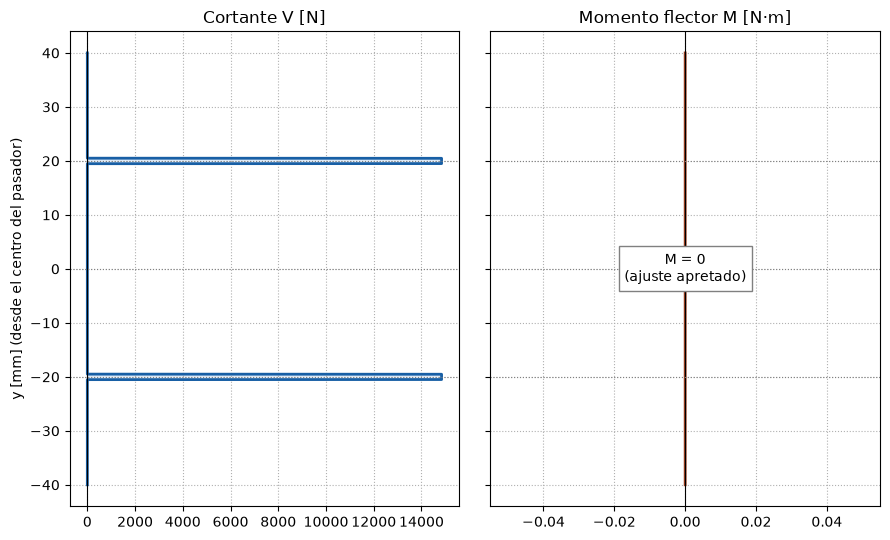

In [4]:
y = np.linspace(hN, -hN, 40001)                                      # [mm] de arriba hacia abajo
dy = y[0] - y[1]
if MODELO == "sin_flexion":                                        # cortante solo en los planos de transición (ancho ~1 mm), sin momento
    V_y = np.where(np.abs(np.abs(y) - D/2) < 0.5, F_cubo, 0.0); M_y = np.zeros_like(y)
else:
    V_y = sum(f*(y < yi) for yi, f, n in cargas)                   # [N]   Σ fuerzas por encima del corte
    M_y = np.cumsum(V_y)*dy/1000 - (T_F*(y < 0) if hay_par else 0.0)   # [N·m] ∫V dy desde arriba (− par en el centro si hay_par)
V_max = float(np.abs(V_y).max()); M_max = float(np.abs(M_y).max())*1000     # [N] , [N·mm]  ← valores de diseño
print(f"Cierre: V(abajo) = {V_y[-1]:.1f} N | M(abajo) = {M_y[-1]:.2e} N·m  (deben ser 0)")
print(f"V máx = {V_max:.0f} N | |M| máx = {M_max/1000:.1f} N·m" + (f" en y = {y[np.argmax(np.abs(M_y))]:.1f} mm" if M_max > 0 else "  (ajuste apretado: no se calcula flexión)"))

fig, ax = plt.subplots(1, 2, figsize=(9, 5.5), sharey=True)
ax[0].plot(V_y, y, "#185FA5", lw=2); ax[0].fill_betweenx(y, V_y, alpha=.25, color="#85B7EB"); ax[0].set_title("Cortante V [N]")
ax[1].plot(M_y, y, "#993C1D", lw=2); ax[1].fill_betweenx(y, M_y, alpha=.25, color="#F0997B"); ax[1].set_title("Momento flector M [N·m]")
for a_x in ax:
    a_x.axvline(0, c="k", lw=.8); a_x.grid(True, ls=":")
    for yy in sorted({c_[0] for c_ in cargas} | {0}): a_x.axhline(yy, ls=":", c="gray", lw=.8)
if M_max == 0: ax[1].text(0, 0, "M = 0\n(ajuste apretado)", ha="center", va="center", bbox=dict(fc="w", ec="gray"))
ax[0].set_ylabel("y [mm] (desde el centro del pasador)"); plt.tight_layout(); plt.show()

## Paso 4 · Esfuerzos máximos (ecuaciones 3 a 7) y Paso 5–6 · Fatiga y fluencia (ecuaciones 8 a 12)
Todo se escribe como función del diámetro $d_p$, porque $d_p$ es la incógnita. Después se evalúa para un $d_p$ cualquiera (paso 7).

**Criterios (cada uno por separado, más el combinado de flexión y corte):**
- **Corte** y **flexión** se revisan solos y también combinados con Von Mises, usando los máximos de ambos (conservador, porque actúan en puntos distintos de la sección).
- **Aplastamiento** (cubo y eje): es compresión, así que $\sigma_m = -\sigma/2 \le 0$ y basta $\sigma_a/S_f$ (diap. 28 de EM1).
- Ciclo 0 → máximo: alterno = medio = máximo/2. $K_f$ del pasador mismo = 1 (la entalla del agujero en el **eje** se revisa aparte, en la verificación del eje).

In [5]:
np.seterr(divide='ignore', invalid='ignore')                         # N = ∞ cuando un esfuerzo vale 0 (p. ej. flexión en sin_flexion)
Cs = 4.51*Sr**-0.265                                               # (9) factor de superficie (mecanizado)
Sf_prima = 0.5*Sr if Sr <= 1400 else 700.0                         # [MPa] límite de fatiga de probeta

def calcular(dp):
    """Esfuerzos y factores de seguridad para un diámetro de pasador dp [mm]. Acepta números o arreglos."""
    dp = np.asarray(dp, float)
    tau   = V_max/(np.pi*dp**2/4)                                      # (3)  [MPa] corte
    sig   = 32*M_max/(np.pi*dp**3)                                 # (4)  [MPa] flexión
    svm   = np.sqrt(sig**2 + 3*tau**2)                             # (5)  [MPa] Von Mises con ambos máximos
    ap_c  = F_cubo/(dp*S)                                               # (6)  [MPa] aplastamiento en el cubo
    ap_e  = 6*T_Nmm/(D**2*dp)                                      # (7)  [MPa] aplastamiento en el eje (pico)
    Ct = 0.879*(dp/25.4)**-0.107                                   # (9)  factor de tamaño
    Sf = Sf_prima*Cc*Ct*Cs*CT*Ci                                   # (8)  [MPa]
    good = lambda s_max: 1/((Kf_pasador*s_max/2)/Sf + (s_max/2)/Sr)  # (10) Goodman con σ_a = σ_m = σ_max/2
    r = dict(tau=tau, sig=sig, svm=svm, ap_c=ap_c, ap_e=ap_e, Sf=Sf,
             Nf_corte=good(np.sqrt(3)*tau), Nf_flex=good(sig), Nf_vm=good(svm),
             Nf_apc=Sf/(Kf_pasador*ap_c/2), Nf_ape=Sf/(Kf_pasador*ap_e/2),            # (11)
             Ny_corte=0.577*S0/tau, Ny_flex=S0/sig, Ny_vm=S0/svm, Ny_apc=S0/ap_c, Ny_ape=S0/ap_e)   # (12)
    return r

CRIT = [("Corte", "tau", "Nf_corte", "Ny_corte"), ("Flexión", "sig", "Nf_flex", "Ny_flex"),
        ("Flexión + corte (Von Mises)", "svm", "Nf_vm", "Ny_vm"),
        ("Aplastamiento en el cubo", "ap_c", "Nf_apc", "Ny_apc"), ("Aplastamiento en el eje", "ap_e", "Nf_ape", "Ny_ape")]
if M_max == 0: CRIT = [c for c in CRIT if not c[0].startswith("Flexión")]   # sin flexión: se descartan esos criterios
print("Función calcular(dp) lista. Ejemplo con dp = 25 mm:")
r = calcular(25); print({k: round(float(v), 2) for k, v in r.items()})

Función calcular(dp) lista. Ejemplo con dp = 25 mm:
{'tau': 30.23, 'sig': 0.0, 'svm': 52.37, 'ap_c': 29.68, 'ap_e': 89.05, 'Sf': 182.47, 'Nf_corte': 5.02, 'Nf_flex': inf, 'Nf_vm': 5.02, 'Nf_apc': 12.29, 'Nf_ape': 4.1, 'Ny_corte': 7.5, 'Ny_flex': inf, 'Ny_vm': 7.5, 'Ny_apc': 13.24, 'Ny_ape': 4.41}


## Paso 7 · Diámetro mínimo y elección (ecuación 13)
Para cada criterio se busca el menor $d_p$ con $N_{fat}\ge N_f$. El diámetro mínimo del pasador es el **mayor** de todos, y se adopta el siguiente de la serie disponible.

MODELO: sin_flexion  |  Criterio que manda: Corte
d_p,min (fatiga, N = 1.6) = 13.81 mm   →   d_p adoptado = 16 mm   (relación d_p/D = 0.40)


,Criterio,Esfuerzo máx [MPa],N fatiga,N fluencia,"d_p,min fatiga [mm]","d_p,min fluencia [mm]",Fatiga ≥ 1.6
0,Corte,73.81,2.13,3.07,13.81,11.55,✔
1,Aplastamiento en el cubo,46.38,8.25,8.47,4.00,4.00,✔
2,Aplastamiento en el eje,139.14,2.75,2.82,8.73,9.07,✔


S_f del pasador (d_p = 16 mm) = 191.4 MPa | C_s = 0.884 | material: SAE 1020 estirado en frío (S0 = 393, Sr = 469 MPa)


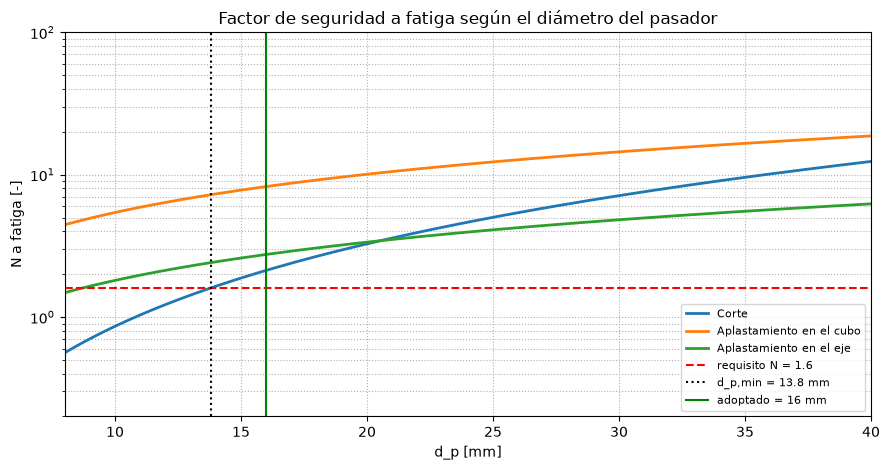

In [6]:
grid = np.arange(4, 60, 0.01)                                      # [mm]
R = calcular(grid)
def primero(N):                                                    # menor dp con N ≥ N_f (N crece con dp)
    ok = N >= N_f; return grid[np.argmax(ok)] if ok.any() else np.nan
dp_min_fat = {n: primero(R[nf]) for n, _, nf, _ in CRIT}
dp_min_flu = {n: primero_y for n, primero_y in [(n, (grid[np.argmax(R[ny] >= N_f)] if (R[ny] >= N_f).any() else np.nan)) for n, _, _, ny in CRIT]}
dp_min = np.nanmax(list(dp_min_fat.values()))
critico = max(dp_min_fat, key=lambda k: dp_min_fat[k])
if dp_adoptado is None:
    dp_adoptado = next((x for x in SERIE_DP if x >= dp_min), None)
    if dp_adoptado is None: dp_adoptado = float(np.ceil(dp_min))
print(f"MODELO: {MODELO}  |  Criterio que manda: {critico}")
print(f"d_p,min (fatiga, N = {N_f}) = {dp_min:.2f} mm   →   d_p adoptado = {dp_adoptado} mm   (relación d_p/D = {dp_adoptado/D:.2f})")

# ---- Tabla final para el d_p adoptado ----
r = calcular(dp_adoptado)
filas = []
for n, s, nf, ny in CRIT:
    filas.append((n, float(r[s]), float(r[nf]), float(r[ny]), dp_min_fat[n], dp_min_flu[n], "✔" if float(r[nf]) >= N_f else "✘"))
TABLA = pd.DataFrame(filas, columns=["Criterio", "Esfuerzo máx [MPa]", "N fatiga", "N fluencia", "d_p,min fatiga [mm]", "d_p,min fluencia [mm]", f"Fatiga ≥ {N_f}"]).round(2)
display(TABLA)
print(f"S_f del pasador (d_p = {dp_adoptado} mm) = {float(r['Sf']):.1f} MPa | C_s = {Cs:.3f} | material: {nombre_mat} (S0 = {S0:.0f}, Sr = {Sr:.0f} MPa)")

# ---- Figura 3: N vs d_p ----
fig, a = plt.subplots(figsize=(9, 4.8))
for n, s, nf, ny in CRIT: a.semilogy(grid, R[nf], label=n, lw=2)
a.axhline(N_f, c="r", ls="--", label=f"requisito N = {N_f}"); a.axvline(dp_min, c="k", ls=":", label=f"d_p,min = {dp_min:.1f} mm"); a.axvline(dp_adoptado, c="g", ls="-", lw=1.5, label=f"adoptado = {dp_adoptado} mm")
a.set_xlim(8, 40); a.set_ylim(.2, 100); a.set_xlabel("d_p [mm]"); a.set_ylabel("N a fatiga [-]"); a.grid(True, which="both", ls=":"); a.legend(fontsize=8); a.set_title("Factor de seguridad a fatiga según el diámetro del pasador"); plt.tight_layout(); plt.show()

## Aclaraciones (léelas antes de usar los números)
1. **Material.** Los valores $S_0$ y $S_r$ son los que entregaste; confirma que vienen de la misma ficha técnica y condición de suministro que usaste para el eje. Para que el pasador sea el "fusible mecánico" debería ser **más débil que el eje y el cubo**: con $S_r = 469$ MPa es más débil a fatiga que el eje ($S_r = 640$), pero su fluencia ($393$ MPa) es **mayor** que la del eje ($340$ MPa).
2. **Modelo y montaje.** `par_centro` concentra la carga del eje en un par en el centro (**sobreestima la flexión**, lado seguro). `repartido` usa las resultantes de la diapositiva 16 (momento menor). Ambos corresponden a un pasador **con holgura**. `sin_flexion` corresponde a un **montaje apretado**, donde no se calcula flexión. La guía del proyecto no fija el montaje: el que elijas debe declararse y justificarse. Cambia `MODELO` en la celda 1 para comparar.
3. **Aplastamiento en el eje.** El modelo no entrega una fuerza en el eje, así que se usa el pico de la distribución triangular de la diapositiva 16: $\sigma_{ap,e}=6T/(D^2 d_p)$.
4. **Von Mises combinado** toma el máximo de flexión y el máximo de corte a la vez, aunque ocurran en puntos distintos de la sección. Los apuntes de la asignatura revisan cada efecto por separado; esa columna también está en la tabla.
5. **Relación $d_p/D$.** Un pasador muy grande **debilita el eje**: el agujero deja una sección neta pequeña ($D-d_p$) y un concentrador de esfuerzo alto en el eje. Esa verificación va en la sección del eje y puede obligar a aumentar el diámetro del eje en F. Revisa la relación impresa en el paso 7.
6. **Ciclo de carga 0 → máximo** supone arranque y parada. Si el profesor no lo pide, con torque constante el pasador giraría con carga casi fija y los $N$ a fatiga serían mayores.
7. **Estos números dependen de supuestos:** reparto de potencia 50/50, material del pasador, y espesor del cubo $S = 20$ mm.


> ✍️ **REDACTAR · Diseño por pasador en polea F** _(borrar este recuadro al terminar)_
>
> - **Tipo de pasador y material:** pasador cilíndrico ⟦liso, ISO 2338 / DIN 7⟧ de ⟦material⟧ ($S_0$ = ⟦…⟧, $S_r$ = ⟦…⟧ MPa), elegido ⟦más blando que el eje para actuar como fusible mecánico⟧.
> - **Montaje:** ⟦con holgura / ajuste apretado sin holgura⟧ y su consecuencia en el cálculo (con o sin flexión).
> - **Modelo de carga:** ⟦par de fuerzas $F = T_F/D$ y momento $T_F$ en el centro (conservador) / cargas repartidas con resultantes $F_D$ y $F_P$ (diap. 16) / sin flexión con $F = T_F/D$ ó $T_F/(D+S)$⟧ y por qué se eligió.
> - **Ciclo y criterio:** carga 0 → máximo por arranque y parada; Goodman con Von Mises; $N_f$ = 1,6.
> - **Resultados:** $F$, $V_{max}$, $M_{max}$, tabla de esfuerzos y factores; $d_{p,min}$ = ⟦…⟧ mm; $d_p$ adoptado = ⟦…⟧ mm.
> - **Fluencia (objetivo 6):** $N_y$ del diseño = ⟦…⟧ (columna "N fluencia" del criterio que manda).
> - **Discusión:** relación $d_p/D$, debilitamiento del eje en F, comparación con el modelo de cargas repartidas y con el modelo clásico sin flexión.